# Test 4: statistical tests

**Question:** does the format of the data in a prompt (CSV, JSON, Markdown, XML or prose) change how many **output tokens** Claude Haiku 4.5 uses when it writes code for it?

**Data:** 12 tasks × 5 formats × 40 runs = 2,400 replies. The experiment itself is in `test4.ipynb`.

**Before the tests**

- **p-value:** if there were really no difference, how surprising would our data be? Below 0.05, we call the difference real.
- **We test averages, not single replies.** The 40 runs of a prompt all come from the same task, so they aren't 40 independent data points. Most tests use the average of each prompt: 60 numbers (12 tasks × 5 formats).
- **We compare formats as ratios.** 1.24× means 24% more output tokens. (Under the hood this uses the log of the token count.)

| # | Test | Question it answers |
|---|---|---|
| 1 | boxplot rule | Why does JSON have extreme outliers? |
| 2 | one-way ANOVA | Do the five formats differ at all? |
| 3 | paired t-test | Which pairs of formats differ, and by how much? |
| 4 | permutation test | Do we get the same answer using all 2,400 replies? |
| 5 | chi-square test | Does the share of working code depend on format? |
| 6 | linear regression | What is each format's effect, with the task held fixed? |
| 7 | simple linear regression | Do longer prompts get longer replies? |
| 8 | logistic regression | What are the odds of working code in each format? |

In [1]:
import ast
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy import stats

SEED, N_PERM, ALPHA = 42, 10_000, 0.05
MODEL = "claude-haiku-4-5"
DATA_FORMATS = ["csv", "json", "markdown", "xml", "prose"]
DATA_COLORS = {"csv": "#008300", "json": "#1d6fb8", "markdown": "#d4762c", "xml": "#4a3aa7", "prose": "#e87ba4"}
DATA_MARKERS = {"csv": "o", "json": "v", "markdown": "^", "xml": "s", "prose": "D"}
INK, MUTED, FAINT = "#262624", "#52514e", "#b5b4ae"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": FAINT,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10})


def p_text(p):
    return "< 0.0001" if p < 1e-4 else f"{p:.4f}"


def say(*lines):
    display(Markdown("\n".join(lines)))


responses = pd.read_csv("../data/format_results.csv")
responses = responses[responses["model"] == MODEL].copy()
responses["task"] = responses["task_id"].str[4:]
responses["data_format"] = pd.Categorical(responses["data_format"], DATA_FORMATS, ordered=True)
responses["log_tokens"] = np.log(responses["output_tokens"])
cid = responses["task_id"] + "__" + responses["data_format"].astype(str) + "__run" + responses["run"].map("{:02d}".format)
responses["reply"] = [Path(f"../data/raw_format/{c}.txt").read_text(encoding="utf-8")
                      if Path(f"../data/raw_format/{c}.txt").exists() else "" for c in cid]

# One row per prompt (task × format): the average of its 40 runs.
prompts = responses.groupby(["task", "data_format"], observed=True).agg(
    log_tokens=("log_tokens", "mean"), output_tokens=("output_tokens", "mean"),
    input_tokens=("input_tokens", "first"), valid_rate=("passed_all", "mean")).reset_index()
task_log = prompts.pivot(index="task", columns="data_format", values="log_tokens")[DATA_FORMATS]
print(f"{len(responses)} replies -> {len(prompts)} prompt averages ({task_log.shape[0]} tasks × {task_log.shape[1]} formats)")

2400 replies -> 60 prompt averages (12 tasks × 5 formats)


## 1. Why does JSON have outliers? (boxplot rule)

**Main idea:** the boxplot rule flags any value far above the middle half of the data (more than 1.5 × the interquartile range above the third quartile). It doesn't say a value is wrong, only that it's worth a look. So we flagged the JSON outliers and read those replies.

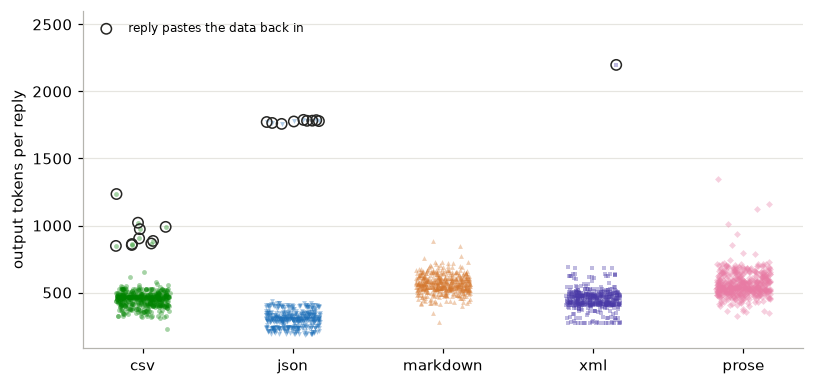

- **9** JSON replies are flagged; **9** of them paste the data back in, all from the `first_tower` task.
- They average **1776** tokens; a normal JSON reply has a median of **304**.
- They raise JSON's mean from 302 to 330; the median doesn't change.

In [2]:
def normalize(text):
    return unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode().lower()


# An "echo" reply copies the prompt's data: more than 2 of the prompt's team or player names appear in it
# (the same rule the grader uses to catch hard-coded data).
names = {t: [normalize(n) for n in ast.literal_eval(re.search(r"PROMPT_NAMES = (\[.*?\])",
         Path(f"../format_tasks/{t}/test_solution.py").read_text(encoding="utf-8"), re.DOTALL).group(1))]
         for t in responses["task_id"].unique()}
responses["echo"] = [sum(n in normalize(r) for n in names[t]) > 2 for t, r in zip(responses["task_id"], responses["reply"])]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
jitter = np.random.default_rng(SEED)
for i, d in enumerate(DATA_FORMATS):
    sub = responses[responses["data_format"] == d]
    x = i + jitter.uniform(-0.18, 0.18, len(sub))
    ax.scatter(x, sub["output_tokens"], s=10, alpha=0.35, color=DATA_COLORS[d], marker=DATA_MARKERS[d], linewidth=0)
    echo = sub["echo"].to_numpy()
    ax.scatter(x[echo], sub.loc[echo, "output_tokens"], s=46, facecolor="none", edgecolor=INK, linewidth=1,
               label="reply pastes the data back in" if i == 0 else None)
ax.set_xticks(range(len(DATA_FORMATS)), DATA_FORMATS)
ax.set_ylabel("output tokens per reply")
ax.set_ylim(top=2600)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

json_rows = responses[responses["data_format"] == "json"]
q1, q3 = np.percentile(json_rows["output_tokens"], [25, 75])
flagged = json_rows[json_rows["output_tokens"] > q3 + 1.5 * (q3 - q1)]
echo_json = json_rows[json_rows["echo"]]
say(f"- **{len(flagged)}** JSON replies are flagged; **{int(flagged['echo'].sum())}** of them paste the data back in, "
    f"all from the `{', '.join(echo_json['task'].unique())}` task.",
    f"- They average **{echo_json['output_tokens'].mean():.0f}** tokens; a normal JSON reply has a median of "
    f"**{json_rows.loc[~json_rows['echo'], 'output_tokens'].median():.0f}**.",
    f"- They raise JSON's mean from {json_rows.loc[~json_rows['echo'], 'output_tokens'].mean():.0f} to "
    f"{json_rows['output_tokens'].mean():.0f}; the median doesn't change.")

**Takeaway:** the outliers aren't random. In those replies the model answered, then pasted the whole 20-row data sample into a "test" at the end. JSON is the wordiest way to write the data, so copying it is very expensive. We **keep** these replies (they're real cost), but this is why we use averages and logs instead of raw means.

## 2. Do the formats differ at all? (one-way ANOVA)

**Main idea:** ANOVA compares how far apart the five format averages are with how much values vary *within* each format. That ratio is **F**. If F is large, the averages are too far apart to be chance. It says *whether* formats differ, not *which* ones.

**η² (eta squared):** the share of the variation explained by format, from 0 to 1.

In [3]:
groups = [prompts.loc[prompts["data_format"] == d, "log_tokens"] for d in DATA_FORMATS]
anova = stats.f_oneway(*groups)
grand = prompts["log_tokens"].mean()
eta2 = sum(len(g) * (g.mean() - grand) ** 2 for g in groups) / ((prompts["log_tokens"] - grand) ** 2).sum()
say(f"**F = {anova.statistic:.1f}, p {p_text(anova.pvalue)}, η² = {eta2:.2f}** (on the 60 prompt averages)")

**F = 37.5, p < 0.0001, η² = 0.73** (on the 60 prompt averages)

**Takeaway:** yes, the formats differ, and format explains most of the variation in output length.

## 3. Which formats differ? (paired t-test)

**Main idea:** for two formats, take the difference in each of the 12 tasks, then ask: is the average difference far from zero? It's **paired** because each task is compared with itself, which removes the fact that some tasks just need longer code.

**Bonferroni correction:** we run 10 tests (one per pair), so some could look significant by luck. We multiply each p-value by 10 to be safe.

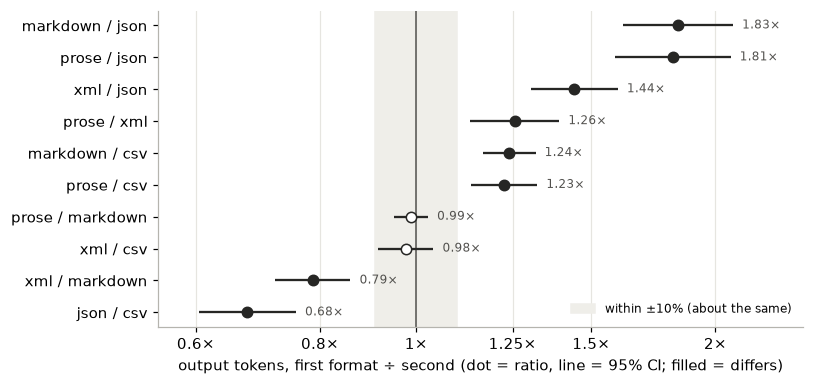

,ratio,CI low,CI high,tasks where higher,p (Bonferroni),differ?
pair,,,,,,
json / csv,0.68,0.60,0.76,1 of 12,< 0.0001,yes
markdown / csv,1.24,1.17,1.32,12 of 12,< 0.0001,yes
xml / csv,0.98,0.91,1.04,5 of 12,1.0000,no
prose / csv,1.23,1.13,1.32,11 of 12,0.0012,yes
markdown / json,1.83,1.62,2.08,12 of 12,< 0.0001,yes
xml / json,1.44,1.30,1.59,11 of 12,< 0.0001,yes
prose / json,1.81,1.59,2.07,12 of 12,< 0.0001,yes
xml / markdown,0.79,0.72,0.86,0 of 12,0.0008,yes
prose / markdown,0.99,0.95,1.03,6 of 12,1.0000,no


In [4]:
PAIRS = [(a, b) for i, b in enumerate(DATA_FORMATS) for a in DATA_FORMATS[i + 1:]]
rows = []
for a, b in PAIRS:
    d = task_log[a] - task_log[b]
    t = stats.ttest_rel(task_log[a], task_log[b])
    ci = t.confidence_interval()
    rows.append({"pair": f"{a} / {b}", "ratio": np.exp(d.mean()), "CI low": np.exp(ci.low), "CI high": np.exp(ci.high),
                 "tasks where higher": f"{(d > 0).sum()} of {len(d)}", "p (Bonferroni)": min(t.pvalue * len(PAIRS), 1)})
pairwise = pd.DataFrame(rows).set_index("pair")
pairwise["differ?"] = np.where(pairwise["p (Bonferroni)"] < ALPHA, "yes", "no")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
plot_rows = pairwise.sort_values("ratio")
ax.axvspan(1 / 1.1, 1.1, color="#efeee9", zorder=0, label="within ±10% (about the same)")
ax.axvline(1, color=MUTED, linewidth=1)
for i, (name, r) in enumerate(plot_rows.iterrows()):
    ax.hlines(i, r["CI low"], r["CI high"], color=INK, linewidth=1.5)
    ax.scatter(r["ratio"], i, s=46, zorder=3, edgecolor=INK, facecolor=INK if r["differ?"] == "yes" else "white")
    ax.annotate(f"{r['ratio']:.2f}×", (r["CI high"], i), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=MUTED)
ax.set_xscale("log")
ax.set_xticks([0.6, 0.8, 1, 1.25, 1.5, 2], ["0.6×", "0.8×", "1×", "1.25×", "1.5×", "2×"])
ax.minorticks_off()
ax.set_xlim(0.55, 2.45)
ax.set_yticks(range(len(plot_rows)), plot_rows.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("output tokens, first format ÷ second (dot = ratio, line = 95% CI; filled = differs)")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

shown = pairwise.copy()
shown["p (Bonferroni)"] = shown["p (Bonferroni)"].map(p_text)
shown.round(2)

**Takeaway:** three groups. **JSON is shortest** (about a third fewer tokens than CSV), **CSV and XML are in the middle**, **Markdown and prose are longest** (about a quarter more than CSV). The two pairs that don't differ, XML / CSV and prose / Markdown, have confidence intervals inside ±10%, so they're about the same, not just "not proven different".

## 4. Same answer with all 2,400 replies? (permutation test)

**Main idea:** if format didn't matter, the format labels would be interchangeable. So within each task we **shuffle the labels** 10,000 times and see how often the shuffled gap is as big as the real one. That share is the p-value. It needs no assumptions about the shape of the data.

It uses all 2,400 replies, so it answers a narrower question: do the formats differ **on these 12 tasks**? This is the test `test4.ipynb` uses.

In [5]:
def permutation_p(a, b):
    rng = np.random.default_rng(SEED)
    observed, shuffled_gap = 0.0, np.zeros(N_PERM)
    for _, g in responses[responses["data_format"].isin([a, b])].groupby("task"):
        ya = g.loc[g["data_format"] == a, "log_tokens"].to_numpy()
        yb = g.loc[g["data_format"] == b, "log_tokens"].to_numpy()
        observed += ya.mean() - yb.mean()
        shuffled = rng.permuted(np.tile(np.concatenate([ya, yb]), (N_PERM, 1)), axis=1)
        shuffled_gap += shuffled[:, :len(ya)].mean(axis=1) - shuffled[:, len(ya):].mean(axis=1)
    return (np.sum(np.abs(shuffled_gap) >= abs(observed)) + 1) / (N_PERM + 1)


compare = pd.DataFrame(index=pairwise.index)
compare["tasks where higher"] = pairwise["tasks where higher"]
compare["permutation p (Bonferroni)"] = [min(permutation_p(a, b) * len(PAIRS), 1) for a, b in PAIRS]
compare["permutation: differ?"] = np.where(compare["permutation p (Bonferroni)"] < ALPHA, "yes", "no")
compare["paired t-test: differ?"] = pairwise["differ?"]
compare["permutation p (Bonferroni)"] = compare["permutation p (Bonferroni)"].map(p_text)
compare

,tasks where higher,permutation p (Bonferroni),permutation: differ?,paired t-test: differ?
pair,,,,
json / csv,1 of 12,0.0010,yes,yes
markdown / csv,12 of 12,0.0010,yes,yes
xml / csv,5 of 12,0.0440,yes,no
prose / csv,11 of 12,0.0010,yes,yes
markdown / json,12 of 12,0.0010,yes,yes
xml / json,11 of 12,0.0010,yes,yes
prose / json,12 of 12,0.0010,yes,yes
xml / markdown,0 of 12,0.0010,yes,yes
prose / markdown,6 of 12,1.0000,no,no


**Takeaway:** the two tests agree on every pair except **XML / CSV**. With all replies, XML and CSV differ, but XML is longer in some tasks and shorter in others. So they differ task by task, with **no overall winner**. Counting 2,400 replies as independent makes a test overconfident about tasks in general.

## 5. Does working code depend on format? (chi-square test)

**Main idea:** validity is yes/no, so we count valid and invalid replies per format and compare those counts with what we'd **expect if format didn't matter**. Big gaps between observed and expected = a large chi-square = format matters.

passed_all,invalid,valid,expected valid,valid rate
data_format,,,,
csv,10,470,391.0,0.979
json,9,471,391.0,0.981
markdown,295,185,391.0,0.385
xml,89,391,391.0,0.815
prose,42,438,391.0,0.912


**χ² = 790, p < 0.0001**

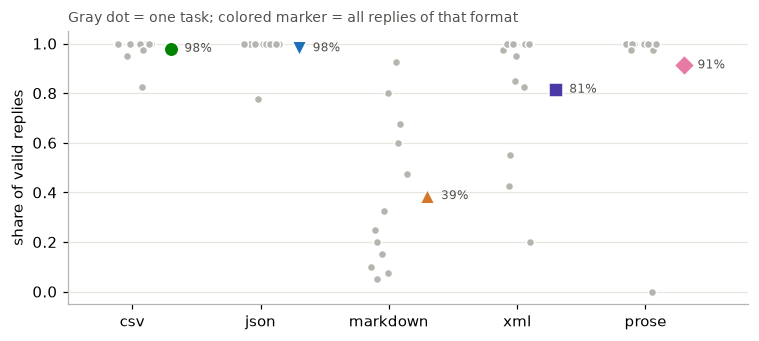

In [6]:
counts = pd.crosstab(responses["data_format"], responses["passed_all"]).rename(columns={False: "invalid", True: "valid"})
chi2 = stats.chi2_contingency(counts)
counts["expected valid"] = chi2.expected_freq[:, 1].round(0)
counts["valid rate"] = counts["valid"] / (counts["valid"] + counts["invalid"])
display(counts.round(3))
say(f"**χ² = {chi2.statistic:.0f}, p {p_text(chi2.pvalue)}**")

task_valid = prompts.pivot(index="task", columns="data_format", values="valid_rate")[DATA_FORMATS]
fig, ax = plt.subplots(figsize=(7, 3.2))
jitter = np.random.default_rng(SEED)
for i, d in enumerate(DATA_FORMATS):
    ax.scatter(i + jitter.uniform(-0.15, 0.15, len(task_valid)), task_valid[d], s=28, color=FAINT, edgecolor="white", zorder=2)
    ax.scatter(i + 0.3, counts.loc[d, "valid rate"], s=90, color=DATA_COLORS[d], marker=DATA_MARKERS[d], edgecolor="white", zorder=3)
    ax.annotate(f"{counts.loc[d, 'valid rate']:.0%}", (i + 0.3, counts.loc[d, "valid rate"]), xytext=(9, 0),
                textcoords="offset points", va="center", fontsize=8, color=MUTED)
ax.set_xticks(range(len(DATA_FORMATS)), DATA_FORMATS)
ax.set_xlim(-0.5, len(DATA_FORMATS) - 0.2)
ax.set_ylabel("share of valid replies")
ax.grid(axis="x", visible=False)
ax.set_title("Gray dot = one task; colored marker = all replies of that format", loc="left", fontsize=9, color=MUTED)
plt.tight_layout()
plt.show()

**Takeaway:** format matters for whether the code works. **Markdown is the clear problem**: it's low in nearly every task. Prose looks worse than it is: almost all its failures come from **one** task. The chi-square test treats every reply as independent, so the per-task dots are needed to tell these apart.

## 6. Each format's effect, task held fixed (linear regression)

**Main idea:** predict a prompt's (log) output tokens from its **format** and its **task**. CSV is the baseline, so each format's coefficient is "how different from CSV, on the same task". We turn coefficients into ratios.

**R²:** the share of variation the model explains, from 0 to 1.

In [7]:
def ols(X, y):
    A, b = X.to_numpy(dtype=float), np.asarray(y, dtype=float)
    coef = np.linalg.lstsq(A, b, rcond=None)[0]
    resid = b - A @ coef
    df = len(b) - A.shape[1]
    se = np.sqrt(np.diag(resid @ resid / df * np.linalg.inv(A.T @ A)))
    table = pd.DataFrame({"coefficient": coef, "p": 2 * stats.t.sf(np.abs(coef / se), df)}, index=X.columns)
    return table, 1 - resid @ resid / ((b - b.mean()) ** 2).sum()


def dummies(series, baseline):
    return pd.get_dummies(series.astype(str)).drop(columns=baseline).astype(float)


intercept = pd.Series(1.0, index=prompts.index, name="intercept")
fmt = dummies(prompts["data_format"], "csv")[DATA_FORMATS[1:]]
task = dummies(prompts["task"], sorted(prompts["task"].unique())[0])
fit, r2_both = ols(pd.concat([intercept, fmt, task], axis=1), prompts["log_tokens"])
_, r2_format = ols(pd.concat([intercept, fmt], axis=1), prompts["log_tokens"])

effects = fit.loc[DATA_FORMATS[1:]].copy()
effects.insert(0, "ratio vs CSV", np.exp(effects["coefficient"]))
effects["p"] = effects["p"].map(p_text)
display(effects.round(3))
say(f"**R² = {r2_both:.2f}** with format and task (format alone: {r2_format:.2f})")

,ratio vs CSV,coefficient,p
json,0.676,-0.391,< 0.0001
markdown,1.240,0.215,< 0.0001
xml,0.975,-0.025,0.5665
prose,1.225,0.203,< 0.0001


**R² = 0.88** with format and task (format alone: 0.73)

**Takeaway:** the same ratios as the paired t-tests, from one model. JSON, Markdown and prose differ from CSV; XML doesn't. Format and task together explain most of why replies differ in length.

## 7. Do longer prompts get longer replies? (simple linear regression)

**Main idea:** fit a straight line through input tokens (prompt length) vs. average output tokens. The **slope** says how output changes per extra input token; **r** (correlation) says how tightly the points follow the line, from −1 to +1.

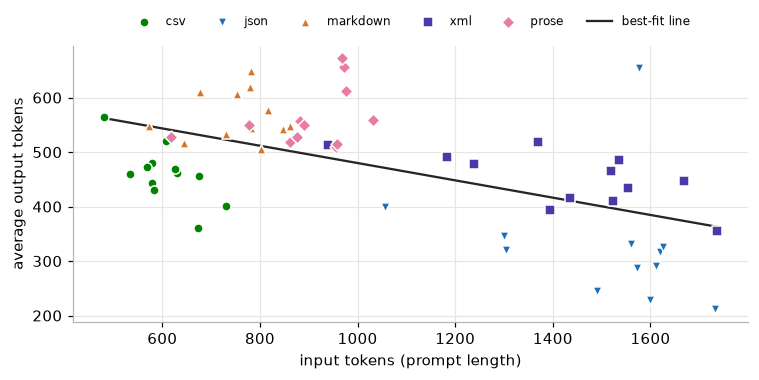

- **All prompts:** slope = -0.16, r = -0.57, p < 0.0001
- **With format held fixed:** slope = -0.11, p = 0.08

In [8]:
line = stats.linregress(prompts["input_tokens"], prompts["output_tokens"])
fig, ax = plt.subplots(figsize=(7, 3.6))
for d in DATA_FORMATS:
    sub = prompts[prompts["data_format"] == d]
    ax.scatter(sub["input_tokens"], sub["output_tokens"], s=36, color=DATA_COLORS[d], marker=DATA_MARKERS[d],
               edgecolor="white", label=d, zorder=3)
xs = np.array([prompts["input_tokens"].min(), prompts["input_tokens"].max()])
ax.plot(xs, line.intercept + line.slope * xs, color=INK, linewidth=1.5, label="best-fit line")
ax.set_xlabel("input tokens (prompt length)")
ax.set_ylabel("average output tokens")
ax.legend(frameon=False, fontsize=8, ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.15))
plt.tight_layout()
plt.show()

held, _ = ols(pd.concat([intercept, prompts["input_tokens"].astype(float), fmt], axis=1), prompts["output_tokens"])
say(f"- **All prompts:** slope = {line.slope:.2f}, r = {line.rvalue:.2f}, p {p_text(line.pvalue)}",
    f"- **With format held fixed:** slope = {held.loc['input_tokens', 'coefficient']:.2f}, p = {held.loc['input_tokens', 'p']:.2f}")

**Takeaway:** at first, longer prompts seem to get *shorter* replies. But that's the formats, not prompt length: JSON and XML make long prompts (right side) and JSON gets short replies. Once we hold format fixed, the relationship isn't significant. This is called **confounding**. The lesson: input cost and output cost have to be measured separately.

## 8. Odds of working code (logistic regression)

**Main idea:** the regression for yes/no outcomes. It predicts the **odds** of a valid reply (chance valid ÷ chance invalid) from format. The **odds ratio** compares each format with CSV: 1 = same as CSV, 0.1 = a tenth of CSV's odds.

In [9]:
def logistic(X, y, steps=30):
    A, b = X.to_numpy(dtype=float), np.asarray(y, dtype=float)
    coef = np.zeros(A.shape[1])
    for _ in range(steps):  # Newton's method, the standard way to fit it
        p = 1 / (1 + np.exp(-A @ coef))
        coef = coef + np.linalg.solve(A.T @ (A * (p * (1 - p))[:, None]), A.T @ (b - p))
    p = 1 / (1 + np.exp(-A @ coef))
    se = np.sqrt(np.diag(np.linalg.inv(A.T @ (A * (p * (1 - p))[:, None]))))
    return pd.DataFrame({"odds ratio vs CSV": np.exp(coef), "p": 2 * stats.norm.sf(np.abs(coef / se))}, index=X.columns)


X = pd.concat([pd.Series(1.0, index=responses.index, name="intercept"),
               dummies(responses["data_format"], "csv")[DATA_FORMATS[1:]]], axis=1)
odds = logistic(X, responses["passed_all"]).loc[DATA_FORMATS[1:]]
odds.insert(0, "valid rate", counts["valid rate"].reindex(odds.index))
odds["p"] = odds["p"].map(p_text)
odds.round(3)

,valid rate,odds ratio vs CSV,p
json,0.981,1.113,0.8168
markdown,0.385,0.013,< 0.0001
xml,0.815,0.093,< 0.0001
prose,0.912,0.222,< 0.0001


**Takeaway:** JSON works as often as CSV (odds ratio near 1). Markdown, XML and prose have much lower odds of working code, Markdown by far the lowest. Like chi-square, this counts every reply separately, so it overstates prose (whose failures come from one task).

## Summary

In [10]:
differ = pairwise.index[pairwise["differ?"] == "yes"]
same = pairwise.index[pairwise["differ?"] == "no"]
say("| Test | Result |", "|---|---|",
    f"| boxplot rule | JSON's {len(flagged)} outliers are replies that paste the data back in, all from one task |",
    f"| one-way ANOVA | formats differ (p {p_text(anova.pvalue)}); format explains {eta2:.0%} of the variation |",
    f"| paired t-test | {len(differ)} of 10 pairs differ; about the same: {', '.join(same)} |",
    f"| permutation test | agrees, except XML / CSV: they differ task by task, with no overall winner |",
    f"| chi-square | working code depends on format (p {p_text(chi2.pvalue)}); Markdown is lowest at {counts.loc['markdown', 'valid rate']:.0%} |",
    f"| linear regression | same ratios vs CSV; format + task explain {r2_both:.0%} of the variation |",
    f"| simple regression | longer prompts don't get longer replies once format is held fixed (p = {held.loc['input_tokens', 'p']:.2f}) |",
    f"| logistic regression | odds of working code: JSON ≈ CSV; Markdown, XML, prose lower |")
say("", "**Bottom line:** JSON gives the shortest replies and works as often as CSV. Markdown and prose give the longest replies, "
    "and Markdown often fails. With only 12 tasks and one model, these results hold for tasks like these.")

| Test | Result |
|---|---|
| boxplot rule | JSON's 9 outliers are replies that paste the data back in, all from one task |
| one-way ANOVA | formats differ (p < 0.0001); format explains 73% of the variation |
| paired t-test | 8 of 10 pairs differ; about the same: xml / csv, prose / markdown |
| permutation test | agrees, except XML / CSV: they differ task by task, with no overall winner |
| chi-square | working code depends on format (p < 0.0001); Markdown is lowest at 39% |
| linear regression | same ratios vs CSV; format + task explain 88% of the variation |
| simple regression | longer prompts don't get longer replies once format is held fixed (p = 0.08) |
| logistic regression | odds of working code: JSON ≈ CSV; Markdown, XML, prose lower |


**Bottom line:** JSON gives the shortest replies and works as often as CSV. Markdown and prose give the longest replies, and Markdown often fails. With only 12 tasks and one model, these results hold for tasks like these.